# inspect reactome + and merge with kegg

Downloaded 20,431 human SwissProt entries

Extracellular/membrane proteins: 5,766
  'Secreted': 2,147
  'Extracellular space': 360
  'Extracellular matrix': 280
  'Cell membrane': 4,045
  'Plasma membrane': 493

Total interactions before filter: 123,895
Interactor 1 extracellular: 37,709
Interactor 2 extracellular: 34,828
Both extracellular (intercellular interactions): 19,788
Removed (intracellular): 104,107
Survival rate: 16.0%
Interactor 1: 19,691 / 19,788 mapped to symbols
Interactor 2: 19,615 / 19,788 mapped to symbols
Both mapped:  19,562 / 19,788
Sample rows:
  uniprot_1 symbol_1 uniprot_2 symbol_2
0    Q9Y287    ITM2B    Q9Y287    ITM2B
1    P37840     SNCA    P37840     SNCA
2    P0DJI8     SAA1    P0DJI8     SAA1
3    P06727    APOA4    P06727    APOA4
4    P01160     NPPA    P01160     NPPA
Removed 3,456 self-interactions, 16,332 remain
Total rows (one per reaction context): 16,332
Unique protein pairs:                  4,843
Average contexts per pair:             3.4

After

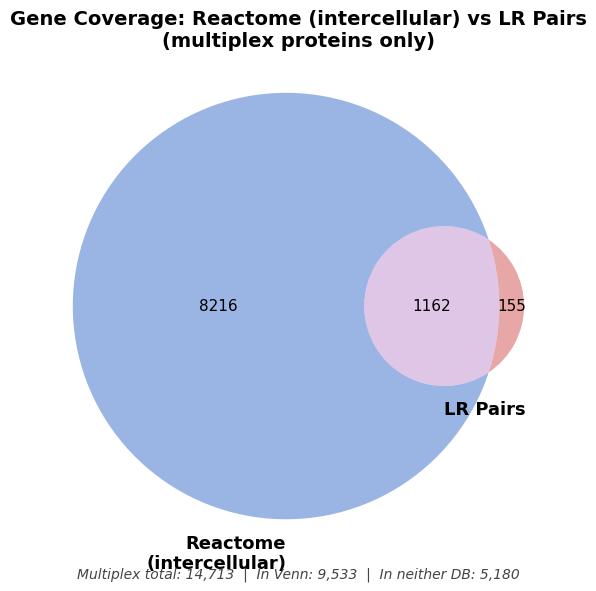

In [22]:
import requests
import pandas as pd
import pickle
import os
import re
import networkx as nx
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib_venn import venn3

# ============================================================================
# 1. DOWNLOAD FUNCTIONS
# ============================================================================

def download_csv(url, output_file, sep='\t', header=None, col_names=None):
    """Generic downloader to avoid repeating try/except blocks."""
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    with open(output_file, 'w') as f:
        f.write(response.text)
    df = pd.read_csv(output_file, sep=sep, header=header)
    if col_names:
        df.columns = col_names
    return df

def download_interactions():
    """
    Downloads Reactome interactions.
    The 'Interaction type' column lets us filter to intercellular events.
    """
    return download_csv(
        url='https://download.reactome.org/96/interactors/reactome.homo_sapiens.interactions.tab-delimited.txt',
        output_file='reactome_interactions_human.txt',
        sep='\t',
        header=0
    )


def filter_intercellular_interactions(interactions_df):
    """
    Keeps only interactions that occur BETWEEN cells (intercellular/extracellular),
    removing purely intracellular interactions.

    Reactome flags intercellular events via the 'Interaction context' column
    and/or specific 'Interaction type' values.

    Strategy:
      - Keep rows where 'Interaction context' contains 'extracellular' or
        'intercellular' (case-insensitive)
      - AND/OR where type indicates a secreted/receptor-mediated event

    Returns filtered DataFrame and prints a summary.
    """
    print(f"Total interactions before filter: {len(interactions_df):,}")
    print(f"\nColumns: {interactions_df.columns.tolist()}")

    # ── Inspect what context values exist ────────────────────────────────────
    if 'Interaction context' in interactions_df.columns:
        print(f"\nInteraction context value counts:")
        print(interactions_df['Interaction context'].value_counts().head(20))
    else:
        print("WARNING: 'Interaction context' column not found.")
        print("Falling back to 'Interaction type' filter only.")

    if 'Interaction type' in interactions_df.columns:
        print(f"\nInteraction type value counts:")
        print(interactions_df['Interaction type'].value_counts().head(20))

    # ── Build intercellular mask ──────────────────────────────────────────────
    mask = pd.Series(False, index=interactions_df.index)

    # Primary filter: context column (most specific)
    if 'Interaction context' in interactions_df.columns:
        context_col = interactions_df['Interaction context'].fillna('')
        mask |= context_col.str.contains(
            'extracellular|intercellular|secreted',
            case=False, regex=True
        )

    # Secondary filter: interaction type (catches ligand-receptor events
    # that Reactome classifies as reactions involving extracellular species)
    if 'Interaction type' in interactions_df.columns:
        type_col = interactions_df['Interaction type'].fillna('')
        # 'reaction' type in Reactome often represents signalling reactions
        # that cross cell boundaries; 'direct_complex' is typically intracellular
        mask |= type_col.str.contains(
            'reaction',          # includes 'neighbouring_reaction' etc.
            case=False, regex=True
        )
        # Explicitly EXCLUDE known intracellular-only types
        intracellular_types = type_col.str.contains(
            'direct_complex|indirect_complex',
            case=False, regex=True
        )
        mask &= ~intracellular_types

    filtered = interactions_df[mask].copy()
    print(f"\nInteractions after intercellular filter: {len(filtered):,}")
    print(f"Removed: {len(interactions_df) - len(filtered):,} intracellular interactions")

    return filtered

def download_uniprot_to_pathways():
    return download_csv(
        url='https://download.reactome.org/96/UniProt2Reactome_All_Levels.txt',
        output_file='uniprot_to_pathways.txt',
        col_names=['uniprot_id', 'reactome_id', 'url', 'pathway_name', 'evidence_code', 'species']
    )


def download_pathway_list():
    return download_csv(
        url='https://download.reactome.org/96/ReactomePathways.txt',
        output_file='pathway_list.txt',
        col_names=['reactome_id', 'pathway_name', 'species']
    )

# ============================================================================
# 2. LOAD LAYERS AND GET MULTIPLEX PROTEINS
# ============================================================================

def load_layers(layers_dir):
    layers = {}
    for fname in sorted(f for f in os.listdir(layers_dir) if f.endswith('_layer.pkl')):
        cell_type = fname.replace('_layer.pkl', '')
        with open(os.path.join(layers_dir, fname), 'rb') as f:
            layers[cell_type] = pickle.load(f)
    print(f"Loaded {len(layers)} layers from {layers_dir}")
    return layers


def get_multiplex_proteins(layers):
    """Return set of all node labels across all layers."""
    proteins = set()
    for layer in layers.values():
        proteins.update(layer.nodes())
    return proteins


def convert_nodes_to_uniprot(layers, symbol_to_uniprot):
    """Relabel graph nodes from gene symbols to UniProt IDs."""
    converted = {}
    for cell_type, layer in layers.items():
        mapping = {
            node: symbol_to_uniprot.get(str(node).upper(), node)
            for node in layer.nodes()
        }
        converted[cell_type] = nx.relabel_nodes(layer, mapping)
    return converted

# ============================================================================
# 3. BUILD PATHWAY LOOKUP  ← this is where your bug lives
# ============================================================================

def build_symbol_pathway_lookup(uniprot_pathways_df, kegg_pathways_df, uniprot_to_symbol):
    """
    Returns a DataFrame with columns:
        gene_symbol | pathway_names (pipe-sep) | sources (pipe-sep)
    """
    # ── Reactome (human only) ─────────────────────────────────────────────────
    reactome = (
        uniprot_pathways_df[uniprot_pathways_df['species'] == 'Homo sapiens']
        [['uniprot_id', 'pathway_name']]
        .copy()
    )
    reactome['gene_symbol'] = (
        reactome['uniprot_id'].map(uniprot_to_symbol).str.upper()
    )
    reactome['source'] = 'Reactome'
    reactome = reactome.dropna(subset=['gene_symbol'])[['gene_symbol', 'pathway_name', 'source']]

    # ── KEGG: diagnose columns first ─────────────────────────────────────────
    print(f"KEGG columns: {kegg_pathways_df.columns.tolist()}")
    print(f"KEGG shape:   {kegg_pathways_df.shape}")
    print(kegg_pathways_df.head(2))

    kegg_raw = kegg_pathways_df[
        ~kegg_pathways_df['gene_name_uniprot'].str.startswith('hsa:', na=False)
    ].copy()

    # Find the symbol column — handle whatever name it actually has
    possible_symbol_cols = ['gene_name_symbol', 'gene_symbol', 'symbol', 'gene_name']
    symbol_col = next((c for c in possible_symbol_cols if c in kegg_raw.columns), None)
    if symbol_col is None:
        raise ValueError(f"Cannot find symbol column in KEGG df. Columns: {kegg_raw.columns.tolist()}")
    print(f"Using KEGG symbol column: '{symbol_col}'")

    # Find the pathway name column
    possible_pathway_cols = ['pathway_name', 'pathway', 'pathway_description', 'name']
    pathway_col = next((c for c in possible_pathway_cols if c in kegg_raw.columns), None)
    if pathway_col is None:
        raise ValueError(f"Cannot find pathway column in KEGG df. Columns: {kegg_raw.columns.tolist()}")
    print(f"Using KEGG pathway column: '{pathway_col}'")

    # Build kegg with standardised column names
    kegg = pd.DataFrame({
        'gene_symbol': kegg_raw[symbol_col].str.upper(),
        'pathway_name': kegg_raw[pathway_col],
        'source': 'KEGG'
    })
    kegg = kegg.dropna(subset=['gene_symbol', 'pathway_name'])

    # Sanity check — make sure pathway_name isn't literally 'pathway'
    bad = (kegg['pathway_name'].str.strip().str.lower() == 'pathway').sum()
    if bad > 0:
        print(f"WARNING: {bad:,} KEGG rows have pathway_name = 'pathway' — dropping them")
        kegg = kegg[kegg['pathway_name'].str.strip().str.lower() != 'pathway']

    print(f"\nReactome rows: {len(reactome):,}")
    print(f"KEGG rows:     {len(kegg):,}")

    # ── Combine and collapse ──────────────────────────────────────────────────
    combined = pd.concat([reactome, kegg], ignore_index=True)

    lookup = (
        combined
        .groupby('gene_symbol', sort=False)
        .agg(
            pathway_names=pd.NamedAgg(column='pathway_name',
                                      aggfunc=lambda x: '|'.join(sorted(set(x)))),
            sources=pd.NamedAgg(column='source',
                                aggfunc=lambda x: '|'.join(sorted(set(x))))
        )
        .reset_index()
    )

    print(f"\nPathway lookup: {len(lookup):,} unique gene symbols, "
          f"{combined['pathway_name'].nunique():,} unique pathways")
    return lookup

def build_symbol_pathway_lookup_reactome_only(uniprot_pathways_df, uniprot_to_symbol):
    reactome = (
        uniprot_pathways_df[uniprot_pathways_df['species'] == 'Homo sapiens']
        [['uniprot_id', 'pathway_name']]
        .copy()
    )

    # ── STRIP WHITESPACE HERE at source ──────────────────────────────────────
    reactome['pathway_name'] = reactome['pathway_name'].str.strip()

    reactome['gene_symbol'] = (
        reactome['uniprot_id']
        .map(uniprot_to_symbol)
        .str.strip()          # strip here too
        .str.upper()
    )
    reactome['source'] = 'Reactome'
    reactome = reactome.dropna(subset=['gene_symbol'])[['gene_symbol', 'pathway_name', 'source']]

    lookup = (
        reactome
        .groupby('gene_symbol', sort=False)
        .agg(
            pathway_names=pd.NamedAgg(
                column='pathway_name',
                aggfunc=lambda x: '|'.join(sorted(set(x.str.strip())))  # strip again in agg
            ),
            sources=pd.NamedAgg(
                column='source',
                aggfunc=lambda x: '|'.join(sorted(set(x)))
            )
        )
        .reset_index()
    )
    return lookup

def add_symbols_to_interactions(intercellular_df, uniprot_to_symbol):
    """
    Reactome interaction file uses 'uniprotkb:XXXX' format.
    Strips prefix, maps to gene symbols, adds symbol columns.
    """
    def strip_and_map(series):
        # Strip 'uniprotkb:' prefix then map to symbol
        uniprot_ids = series.str.replace('uniprotkb:', '', regex=False).str.strip()
        symbols = uniprot_ids.map(uniprot_to_symbol).str.upper()
        return uniprot_ids, symbols

    col_1 = '# Interactor 1 uniprot id'
    col_2 = 'Interactor 2 uniprot id'

    df = intercellular_df.copy()

    id1, sym1 = strip_and_map(df[col_1])
    id2, sym2 = strip_and_map(df[col_2])

    df['uniprot_1'] = id1
    df['symbol_1']  = sym1
    df['uniprot_2'] = id2
    df['symbol_2']  = sym2

    # Diagnostics
    total = len(df)
    mapped_1 = sym1.notna().sum()
    mapped_2 = sym2.notna().sum()
    both     = (sym1.notna() & sym2.notna()).sum()

    print(f"Interactor 1: {mapped_1:,} / {total:,} mapped to symbols")
    print(f"Interactor 2: {mapped_2:,} / {total:,} mapped to symbols")
    print(f"Both mapped:  {both:,} / {total:,}")
    print(f"Sample rows:")
    print(df[['uniprot_1', 'symbol_1', 'uniprot_2', 'symbol_2']].head(5))

    return df

def map_lr_to_pathways(lr_df, lookup_df):
    idx = lookup_df.set_index('gene_symbol')

    def get_field(gene, field):
        gene_up = str(gene).strip().upper() if pd.notna(gene) else None
        if gene_up and gene_up in idx.index:
            return idx.at[gene_up, field]
        return None

    result = lr_df.copy()
    result['ligand_pathways']   = result['ligand_gname'].map(lambda g: get_field(g, 'pathway_names'))
    result['receptor_pathways'] = result['receptor_gname'].map(lambda g: get_field(g, 'pathway_names'))

    def common_pathways(row):
        # Strip every individual pathway name when comparing
        p1 = {p.strip() for p in row['ligand_pathways'].split('|')}   if pd.notna(row['ligand_pathways'])   else set()
        p2 = {p.strip() for p in row['receptor_pathways'].split('|')} if pd.notna(row['receptor_pathways']) else set()
        common = p1 & p2
        return '|'.join(sorted(common)) if common else None

    result['common_pathways']   = result.apply(common_pathways, axis=1)
    result['n_common_pathways'] = result['common_pathways'].apply(
        lambda x: len(x.split('|')) if pd.notna(x) else 0
    )
    return result

# ============================================================================
# 5. VENN DIAGRAM HELPER
# ============================================================================

def plot_venn(reactome_syms, kegg_syms, lr_syms, multiplex_syms, save_path='venn.png'):
    r_only  = reactome_syms - kegg_syms - lr_syms
    k_only  = kegg_syms - reactome_syms - lr_syms
    lr_only = lr_syms - reactome_syms - kegg_syms
    r_k     = (reactome_syms & kegg_syms) - lr_syms
    r_lr    = (reactome_syms & lr_syms) - kegg_syms
    k_lr    = (kegg_syms & lr_syms) - reactome_syms
    r_k_lr  = reactome_syms & kegg_syms & lr_syms
    in_none = multiplex_syms - reactome_syms - kegg_syms - lr_syms

    fig, ax = plt.subplots(figsize=(9, 7))
    v = venn3(
        subsets=(len(r_only), len(k_only), len(r_k),
                 len(lr_only), len(r_lr), len(k_lr), len(r_k_lr)),
        set_labels=('Reactome', 'KEGG', 'LR Pairs'),
        ax=ax, alpha=0.55,
        set_colors=('#4878CF', '#6ACC65', '#D65F5F'),
    )
    for lbl in v.set_labels:
        if lbl: lbl.set_fontsize(13); lbl.set_fontweight('bold')
    for lbl in v.subset_labels:
        if lbl: lbl.set_fontsize(11)

    ax.set_title('Gene Coverage: Reactome, KEGG, LR Pairs\n(multiplex proteins only)',
                 fontsize=14, fontweight='bold')
    ax.annotate(
        f"Multiplex total: {len(multiplex_syms):,}  |  Not in any DB: {len(in_none):,}",
        xy=(0.5, -0.04), xycoords='axes fraction',
        ha='center', fontsize=10, color='#444', style='italic'
    )
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved {save_path}")

from matplotlib_venn import venn2

def plot_venn_reactome_only(reactome_syms, lr_syms, multiplex_syms,
                             save_path='venn_reactome_lr.png'):
    
    # Restrict everything to multiplex proteins only
    reactome_syms = reactome_syms & multiplex_syms
    lr_syms       = lr_syms       & multiplex_syms

    r_only  = reactome_syms - lr_syms
    lr_only = lr_syms - reactome_syms
    both    = reactome_syms & lr_syms
    in_none = multiplex_syms - reactome_syms - lr_syms

    # These should now sum correctly
    accounted = len(r_only) + len(lr_only) + len(both) + len(in_none)
    assert accounted == len(multiplex_syms), \
        f"Counts don't add up: {accounted} != {len(multiplex_syms)}"

    print(f"Reactome only:  {len(r_only):,}")
    print(f"LR only:        {len(lr_only):,}")
    print(f"Both:           {len(both):,}")
    print(f"In neither:     {len(in_none):,}")
    print(f"Total multiplex:{len(multiplex_syms):,}")
    print(f"Sum of parts:   {accounted:,}")  # should match total

    fig, ax = plt.subplots(figsize=(8, 6))
    v = venn2(
        subsets=(len(r_only), len(lr_only), len(both)),
        set_labels=('Reactome\n(intercellular)', 'LR Pairs'),
        ax=ax, alpha=0.55,
        set_colors=('#4878CF', '#D65F5F'),
    )
    for lbl in v.set_labels:
        if lbl:
            lbl.set_fontsize(13)
            lbl.set_fontweight('bold')
    for lbl in v.subset_labels:
        if lbl:
            lbl.set_fontsize(11)

    ax.set_title(
        'Gene Coverage: Reactome (intercellular) vs LR Pairs\n(multiplex proteins only)',
        fontsize=14, fontweight='bold'
    )
    # Now the numbers in the annotation are consistent with the diagram
    ax.annotate(
        f"Multiplex total: {len(multiplex_syms):,}  "
        f"|  In Venn: {len(reactome_syms | lr_syms):,}  "
        f"|  In neither DB: {len(in_none):,}",
        xy=(0.5, -0.04), xycoords='axes fraction',
        ha='center', fontsize=10, color='#444', style='italic'
    )
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

def download_uniprot_subcellular_locations():
    """
    Downloads UniProt subcellular location annotations for human proteins.
    Filters to extracellular/secreted proteins which are candidates for
    intercellular interactions.
    """
    url = (
        'https://rest.uniprot.org/uniprotkb/stream?'
        'query=organism_id:9606+AND+reviewed:true'  # human SwissProt only
        '&fields=accession,cc_subcellular_location'
        '&format=tsv'
    )
    print("Downloading UniProt subcellular locations (human SwissProt)...")
    response = requests.get(url, timeout=120)
    response.raise_for_status()

    with open('uniprot_subcellular_human.tsv', 'w') as f:
        f.write(response.text)

    df = pd.read_csv('uniprot_subcellular_human.tsv', sep='\t')
    df.columns = ['uniprot_id', 'subcellular_location']
    print(f"Downloaded {len(df):,} human SwissProt entries")
    return df


def get_extracellular_proteins(subcellular_df):
    """
    Returns set of UniProt IDs annotated as extracellular/secreted.
    These are proteins capable of mediating intercellular interactions.

    Keeps proteins with any of these location terms:
      - Secreted
      - Extracellular space
      - Cell membrane (surface receptors)
      - Extracellular matrix
    """
    # Terms that indicate a protein is accessible outside the cell
    intercellular_terms = [
        'Secreted',
        'Extracellular space',
        'Extracellular matrix',
        'Cell membrane',      # surface receptors
        'Plasma membrane',
    ]
    pattern = '|'.join(intercellular_terms)

    mask = subcellular_df['subcellular_location'].str.contains(
        pattern, case=False, na=False
    )
    extracellular = subcellular_df[mask]['uniprot_id'].tolist()
    extracellular_set = set(extracellular)

    print(f"\nExtracellular/membrane proteins: {len(extracellular_set):,}")

    # Breakdown by term
    for term in intercellular_terms:
        n = subcellular_df['subcellular_location'].str.contains(
            term, case=False, na=False
        ).sum()
        print(f"  '{term}': {n:,}")

    return extracellular_set


def filter_intercellular_interactions(interactions_df, extracellular_proteins):
    """
    Keeps interactions where BOTH interactors have extracellular/membrane
    annotations — i.e. the interaction can plausibly occur between cells.

    Logic:
      - Interactor 1 must be extracellular/membrane (ligand side)
      - Interactor 2 must be extracellular/membrane (receptor side)
      - Using AND because we want confirmed intercellular pairs, not just
        one side being extracellular

    If you want to be more permissive (either side), change & to |.
    """
    print(f"\nTotal interactions before filter: {len(interactions_df):,}")

    # Extract UniProt IDs — column names have spaces so reference carefully
    col_1 = '# Interactor 1 uniprot id'
    col_2 = 'Interactor 2 uniprot id'

    # UniProt IDs may be prefixed with 'uniprotkb:' — strip if so
    def strip_prefix(series):
        return series.str.replace(r'^uniprotkb:', '', regex=True).str.strip()

    id1 = strip_prefix(interactions_df[col_1])
    id2 = strip_prefix(interactions_df[col_2])

    mask_1 = id1.isin(extracellular_proteins)
    mask_2 = id2.isin(extracellular_proteins)

    # BOTH must be extracellular/membrane for a true intercellular interaction
    mask = mask_1 & mask_2

    filtered = interactions_df[mask].copy()

    print(f"Interactor 1 extracellular: {mask_1.sum():,}")
    print(f"Interactor 2 extracellular: {mask_2.sum():,}")
    print(f"Both extracellular (intercellular interactions): {len(filtered):,}")
    print(f"Removed (intracellular): {len(interactions_df) - len(filtered):,}")
    print(f"Survival rate: {len(filtered) / len(interactions_df) * 100:.1f}%")

    return filtered

# ============================================================================
# MAIN PIPELINE — Reactome intercellular only, no KEGG
# ============================================================================

# --- Downloads ---
interactions_df     = download_interactions()
uniprot_pathways_df = download_uniprot_to_pathways()
subcellular_df      = download_uniprot_subcellular_locations()

# --- UniProt <-> symbol mapping ---
mapping_df        = pd.read_csv('../../og_gene_set/ppi_chloe/d_uniprot_to_symbol_20251120.csv')
uniprot_to_symbol = dict(zip(mapping_df['uniprotid'], mapping_df['symbol']))
symbol_to_uniprot = {v.upper(): k for k, v in uniprot_to_symbol.items()}

# --- Filter interactions to intercellular only ---
extracellular_proteins        = get_extracellular_proteins(subcellular_df)
intercellular_interactions_df = filter_intercellular_interactions(
    interactions_df, extracellular_proteins
)

# --- Add gene symbols to interaction file ---
intercellular_interactions_df = add_symbols_to_interactions(
    intercellular_interactions_df, uniprot_to_symbol
)

# Add this after add_symbols_to_interactions() -> removing self-loops (homodimers)
before = len(intercellular_interactions_df)
intercellular_interactions_df = intercellular_interactions_df[
    intercellular_interactions_df['uniprot_1'] != intercellular_interactions_df['uniprot_2']
].copy()
after = len(intercellular_interactions_df)
print(f"Removed {before - after:,} self-interactions, {after:,} remain")

# Saving two separate dfs - one with duplicate pairs, one with unique ones
total_rows   = len(intercellular_interactions_df)
unique_pairs = intercellular_interactions_df[['uniprot_1', 'uniprot_2']].apply(
    lambda r: tuple(sorted([r['uniprot_1'], r['uniprot_2']])), axis=1
).nunique()

print(f"Total rows (one per reaction context): {total_rows:,}")
print(f"Unique protein pairs:                  {unique_pairs:,}")
print(f"Average contexts per pair:             {total_rows/unique_pairs:.1f}")

# For most downstream uses you want unique pairs only:
intercellular_unique = intercellular_interactions_df.copy()
intercellular_unique['pair_key'] = intercellular_unique.apply(
    lambda r: tuple(sorted([r['uniprot_1'], r['uniprot_2']])), axis=1
)

# Keep all reaction contexts as a collapsed column, then deduplicate
intercellular_unique = (
    intercellular_unique
    .groupby('pair_key', sort=False)
    .agg(
        uniprot_1=('uniprot_1', 'first'),
        symbol_1=('symbol_1',  'first'),
        uniprot_2=('uniprot_2', 'first'),
        symbol_2=('symbol_2',  'first'),
        interaction_types=('Interaction type',    
                           lambda x: '|'.join(sorted(set(x.dropna())))),
        n_reaction_contexts=('Interaction context', 'count'),  # how many times this pair appears
        reaction_contexts=('Interaction context',  
                           lambda x: '|'.join(sorted(set(x.dropna()))))
    )
    .reset_index(drop=True)
)

print(f"\nAfter deduplication: {len(intercellular_unique):,} unique pairs")
print(intercellular_unique.head())

# Save both versions
intercellular_interactions_df.to_csv(
    'reactome_intercellular_interactions_full.csv', index=False
)  # one row per reaction context
intercellular_unique.to_csv(
    'reactome_intercellular_interactions_unique_pairs.csv', index=False
)  # one row per protein pair, contexts collapsed

# --- Layers ---
layers_1 = load_layers("../multiplex_ts/layers")
layers_2 = load_layers("../multiplex_2025hdrg/layers")
layers   = {**layers_1, **layers_2}

converted_layers   = convert_nodes_to_uniprot(layers, symbol_to_uniprot)
multiplex_proteins = get_multiplex_proteins(converted_layers)
multiplex_symbols  = {
    uniprot_to_symbol[p].upper()
    for p in multiplex_proteins
    if p in uniprot_to_symbol
}
print(f"Multiplex: {len(multiplex_proteins):,} UniProt IDs → {len(multiplex_symbols):,} gene symbols")

# --- Reactome-only pathway lookup ---
lookup_df = build_symbol_pathway_lookup_reactome_only(uniprot_pathways_df, uniprot_to_symbol)

# --- LR pairs ---
lr_pairs = pd.read_csv('human_lr_pairs.csv')

# --- Validate symbol overlap before mapping ---
lr_all = (
    set(lr_pairs['ligand_gname'].str.upper().dropna()) |
    set(lr_pairs['receptor_gname'].str.upper().dropna())
)
reactome_syms_in_interactions = (
    set(intercellular_interactions_df['symbol_1'].dropna()) |
    set(intercellular_interactions_df['symbol_2'].dropna())
)
overlap = lr_all & reactome_syms_in_interactions
print(f"\nLR pair genes in Reactome intercellular interactions: "
      f"{len(overlap):,} / {len(lr_all):,} ({100*len(overlap)/len(lr_all):.1f}%)")

# Spot check known pairs in intercellular interactions
known_pairs = [('ACKR1', 'CCL2'), ('TGFB1', 'TGFBR1'), ('IL6', 'IL6R')]
print("\nSpot checks in intercellular interaction file:")
for lig, rec in known_pairs:
    found = (
        (
            (intercellular_interactions_df['symbol_1'] == lig) &
            (intercellular_interactions_df['symbol_2'] == rec)
        ) | (
            (intercellular_interactions_df['symbol_1'] == rec) &
            (intercellular_interactions_df['symbol_2'] == lig)
        )
    ).any()
    print(f"  {lig} ↔ {rec}: {'✅' if found else '❌ MISSING'}")

# --- Map LR pairs to pathways ---
lr_with_pathways = map_lr_to_pathways(lr_pairs, lookup_df)
lr_with_pathways.to_csv(
    'lr_pairs_with_reactome_intercellular_pathways.csv', index=False
)

# --- Summary ---
total      = len(lr_with_pathways)
has_common = lr_with_pathways['common_pathways'].notna().sum()
print(f"\nLR pairs with ≥1 shared pathway: {has_common:,} / {total:,} "
      f"({100*has_common/total:.1f}%)")

print("\nTop 20 shared pathways:")
counter = Counter(
    p for val in lr_with_pathways['common_pathways'].dropna()
    for p in val.split('|')
)
for pathway, n in counter.most_common(20):
    print(f"  {n:>5}  {pathway}")

# --- 2-circle Venn (no KEGG) ---
lr_syms = (
    set(lr_pairs['ligand_gname'].str.upper().dropna()) |
    set(lr_pairs['receptor_gname'].str.upper().dropna())
) & multiplex_symbols

reactome_syms = (
    set(lookup_df.loc[
        lookup_df['sources'].str.contains('Reactome', na=False),
        'gene_symbol'
    ]) & multiplex_symbols
)

plot_venn_reactome_only(
    reactome_syms, lr_syms, multiplex_symbols,
    save_path='venn_multiplex_reactome_intercellular.png'
)
